# House Prices: from a baseline to a submission

Predict the final sale price of homes in Ames, Iowa. This notebook records
our first experiment session: the data audit, validation design, feature
comparisons, model comparisons, and submission candidates. The tables below
report **local validation**; they do not establish a Kaggle score or rank.

**Read:** use the saved outputs to review the work. **Run:** keep this notebook
beside the local competition data and `results/`, or attach the official
competition data to a Kaggle notebook. The source is embedded below; you do
not need to upload the two Python modules. If the saved tables are absent,
Run All trains the models and writes `results/` and `submissions/`.

In [1]:
from pathlib import Path
import json
import hashlib
import sys
from types import ModuleType

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

RUN_EXPERIMENTS = False  # True forces a fresh run even if results exist.
INCLUDE_OUTLIER_COMPARISON = True
DATA_DIR = None  # Or set Path('/path/to/folder/with/train.csv').

COMPETITION = 'house-prices-advanced-regression-techniques'
kaggle_working = Path('/kaggle/working')
OUTPUT_DIR = kaggle_working if kaggle_working.is_dir() else Path.cwd()
RESULTS = OUTPUT_DIR / 'results'

candidates = [Path.cwd() / COMPETITION, Path.cwd(),
              Path('/kaggle/input') / COMPETITION,
              Path('/kaggle/input/competitions') / COMPETITION]
if DATA_DIR is None:
    DATA_DIR = next((path for path in candidates if (path / 'train.csv').is_file()), None)
else:
    DATA_DIR = Path(DATA_DIR)

def _project_module(name, source):
    # Register an in-memory module, so imports and dataclasses work normally.
    source = source.lstrip('\n')
    module = ModuleType(name)
    module.__file__ = str(Path.cwd() / (name + '.py'))
    module.__source__ = source
    sys.modules[name] = module
    exec(compile(source, module.__file__, 'exec'), module.__dict__)
    return module

## 1. Reusable code

Expand the next two code cells to inspect the feature builder, preprocessing
pipelines, cross-validation loop and experiment runner. They contain the same
source as the local scripts and run directly in the notebook kernel.

In [2]:
hp = _project_module('house_prices', r'''
"""Leakage-aware building blocks for the House Prices coursework experiments."""
from pathlib import Path
import time

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR


ALL_GROUPS = ("semantic", "size", "age", "quality", "log")


def read_competition_csv(path):
    # `None` is a real masonry category. Only the documented NA token is missing.
    return pd.read_csv(path, keep_default_na=False, na_values=["NA", ""])


def load_data(path):
    path = Path(path)
    train = read_competition_csv(path / "train.csv")
    test = read_competition_csv(path / "test.csv")
    sample = read_competition_csv(path / "sample_submission.csv")
    if "SalePrice" not in train or "SalePrice" in test:
        raise ValueError("Expected labeled train.csv and unlabeled test.csv.")
    if train.drop(columns="SalePrice").columns.tolist() != test.columns.tolist():
        raise ValueError("Train/test predictor schemas differ.")
    if not train.Id.is_unique or not test.Id.is_unique or not sample.Id.is_unique:
        raise ValueError("Ids must be unique in each file.")
    if set(train.Id) & set(test.Id):
        raise ValueError("Training and test Ids overlap.")
    if test.Id.tolist() != sample.Id.tolist():
        raise ValueError("Sample submission and test Id order differ.")
    if not np.isfinite(train.SalePrice).all() or (train.SalePrice <= 0).any():
        raise ValueError("Training prices must be positive and finite.")
    return train, test, sample


class FeatureBuilder(TransformerMixin, BaseEstimator):
    """Deterministic row-wise features; no target or population statistics."""
    def __init__(self, groups=ALL_GROUPS):
        self.groups = groups

    def fit(self, X, y=None):
        invalid = set(self.groups) - set(ALL_GROUPS)
        if invalid:
            raise ValueError(f"Unknown feature groups: {invalid}")
        self.feature_names_in_ = [c for c in X.columns if c not in ("Id", "SalePrice")]
        return self

    def transform(self, X):
        data = X.loc[:, self.feature_names_in_].copy()
        if "MSSubClass" in data:
            data["MSSubClass"] = data["MSSubClass"].map(
                lambda value: str(int(value)) if pd.notna(value) else np.nan)
        if "semantic" in self.groups:
            absent_groups = [
                ("TotalBsmtSF", ("BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"), "NoBasement"),
                ("Fireplaces", ("FireplaceQu",), "NoFireplace"),
                ("PoolArea", ("PoolQC",), "NoPool"),
            ]
            for measure, columns, absence in absent_groups:
                if measure in data:
                    for column in columns:
                        if column in data:
                            fill = pd.Series(np.where(data[measure].eq(0), absence, "Unknown"), index=data.index)
                            data[column] = data[column].fillna(fill)
            if {"GarageCars", "GarageArea"}.issubset(data.columns):
                no_garage = data.GarageCars.eq(0) & data.GarageArea.eq(0)
                for column in ("GarageType", "GarageFinish", "GarageQual", "GarageCond"):
                    if column in data:
                        data[column] = data[column].fillna(pd.Series(
                            np.where(no_garage, "NoGarage", "Unknown"), index=data.index))
            for column, absence in (("Alley", "NoAlley"), ("Fence", "NoFence"),
                                    ("MiscFeature", "NoMiscFeature"), ("MasVnrType", "Unknown")):
                if column in data:
                    data[column] = data[column].fillna(absence)
            if {"GarageYrBlt", "YrSold"}.issubset(data.columns):
                # A reported 2207 garage date is impossible for a 2000s sale;
                # keep a flag and impute inside each fold instead of guessing 2007.
                impossible = (data.GarageYrBlt > data.YrSold + 2) | (data.GarageYrBlt < 1700)
                data["GarageYearInvalid"] = impossible.astype(int)
                data.loc[impossible, "GarageYrBlt"] = np.nan

        if "size" in self.groups:
            totals = {
                "TotalSF": ("GrLivArea", "TotalBsmtSF"),
                "TotalFinishedSF": ("GrLivArea", "BsmtFinSF1", "BsmtFinSF2"),
                "TotalPorchSF": ("WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"),
            }
            for name, columns in totals.items():
                if set(columns).issubset(data.columns):
                    data[name] = data[list(columns)].sum(axis=1, min_count=len(columns))
            bathrooms = ("FullBath", "BsmtFullBath", "HalfBath", "BsmtHalfBath")
            if set(bathrooms).issubset(data.columns):
                data["TotalBathrooms"] = (data.FullBath + data.BsmtFullBath +
                                            0.5 * (data.HalfBath + data.BsmtHalfBath))
            for column, name in (("TotalBsmtSF", "HasBasement"), ("GarageArea", "HasGarage"),
                                 ("PoolArea", "HasPool"), ("Fireplaces", "HasFireplace"),
                                 ("2ndFlrSF", "HasSecondFloor")):
                if column in data:
                    data[name] = np.where(data[column].isna(), np.nan, data[column].gt(0).astype(float))

        if "age" in self.groups and "YrSold" in data:
            for column, name in (("YearBuilt", "HouseAge"), ("YearRemodAdd", "RemodelAge"),
                                 ("GarageYrBlt", "GarageAge")):
                if column in data:
                    data[name] = (data.YrSold - data[column]).clip(lower=0)
            if "YearRemodAdd" in data:
                data["RemodelAfterSale"] = data.YearRemodAdd.gt(data.YrSold).astype(int)
                if "YearBuilt" in data:
                    data["WasRemodeled"] = data.YearRemodAdd.gt(data.YearBuilt).astype(int)

        if "quality" in self.groups:
            quality = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1,
                       "NoBasement": 0, "NoGarage": 0, "NoFireplace": 0, "NoPool": 0}
            for column in ("ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                           "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"):
                if column in data:
                    data[column + "Score"] = data[column].map(quality)
            if {"OverallQual", "GrLivArea"}.issubset(data.columns):
                data["QualityLivingArea"] = data.OverallQual * data.GrLivArea
            if {"OverallQual", "TotalBsmtSF", "GrLivArea"}.issubset(data.columns):
                data["QualityTotalArea"] = data.OverallQual * (data.GrLivArea + data.TotalBsmtSF)

        if "log" in self.groups:
            columns = ("LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
                       "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF",
                       "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
                       "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal", "TotalSF",
                       "TotalFinishedSF", "TotalPorchSF", "QualityLivingArea", "QualityTotalArea")
            for column in columns:
                if column in data:
                    if data[column].dropna().lt(0).any():
                        raise ValueError(f"Unexpected negative area/value in {column}")
                    data[column] = np.log1p(data[column])
        return data


class NativeCatBoost(RegressorMixin, BaseEstimator):
    """Keep native categories, with unknown category markers and numeric NaNs."""
    def __init__(self, parameters=None, seed=42):
        self.parameters = parameters
        self.seed = seed

    def _prepare(self, X):
        data = X.copy()
        for column in self.categorical_columns_:
            data[column] = data[column].fillna("Unknown").astype(str)
        return data

    def fit(self, X, y):
        from catboost import CatBoostRegressor
        self.categorical_columns_ = X.select_dtypes(exclude=np.number).columns.tolist()
        settings = dict(iterations=1800, depth=5, learning_rate=0.035, l2_leaf_reg=5,
                        loss_function="RMSE", random_seed=self.seed, thread_count=4,
                        verbose=False, allow_writing_files=False)
        settings.update(self.parameters or {})
        self.model_ = CatBoostRegressor(**settings, cat_features=self.categorical_columns_)
        self.model_.fit(self._prepare(X), y)
        return self

    def predict(self, X):
        return self.model_.predict(self._prepare(X))


def make_model(kind, groups=ALL_GROUPS, parameters=None, seed=42):
    parameters = parameters or {}
    features = FeatureBuilder(groups=groups)
    if kind == "catboost":
        return Pipeline([("features", features), ("model", NativeCatBoost(parameters, seed))])
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True,
                                                   keep_empty_features=True)),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown",
                                                       keep_empty_features=True)),
                            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    preprocess = ColumnTransformer([
        ("numeric", numeric, make_column_selector(dtype_include=np.number)),
        ("categorical", categorical, make_column_selector(dtype_exclude=np.number)),
    ])
    if kind == "dummy":
        model = DummyRegressor(strategy="mean")
    elif kind == "ridge":
        model = Ridge(**({"alpha": 20.0} | parameters))
    elif kind == "elasticnet":
        model = ElasticNet(**({"alpha": 0.0005, "l1_ratio": 0.9, "max_iter": 30000,
                               "tol": 1e-5, "random_state": seed} | parameters))
    elif kind == "svr":
        model = SVR(**({"C": 20, "epsilon": 0.008, "gamma": 0.0005} | parameters))
    elif kind == "xgboost":
        from xgboost import XGBRegressor
        settings = dict(n_estimators=1800, max_depth=3, learning_rate=0.025,
                        subsample=0.8, colsample_bytree=0.8, min_child_weight=2,
                        reg_alpha=0.02, reg_lambda=5, tree_method="hist", n_jobs=4,
                        random_state=seed, objective="reg:squarederror")
        model = XGBRegressor(**(settings | parameters))
    else:
        raise ValueError(f"Unknown model: {kind}")
    return Pipeline([("features", features), ("preprocess", preprocess), ("model", model)])


def make_folds(n_rows, seed=42):
    return list(KFold(n_splits=5, shuffle=True, random_state=seed).split(np.arange(n_rows)))


def training_keep_mask(X, y, exclude_outliers=False):
    if exclude_outliers:
        return ~((X.GrLivArea.to_numpy() > 4000) & (np.asarray(y) < 300000))
    return np.ones(len(X), dtype=bool)


def evaluate_model(model, X, y, X_test, folds, exclude_outliers=False):
    started = time.perf_counter()
    y = np.asarray(y, dtype=float)
    y_log = np.log(y)
    oof = np.full(len(X), np.nan)
    coverage = np.zeros(len(X), dtype=int)
    test_predictions, fold_records = [], []
    for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
        if set(train_idx) & set(valid_idx):
            raise ValueError("Training and validation indices overlap.")
        keep = training_keep_mask(X.iloc[train_idx], y[train_idx], exclude_outliers)
        fit_idx = train_idx[keep]
        estimator = clone(model)
        estimator.fit(X.iloc[fit_idx], y_log[fit_idx])
        pred = estimator.predict(X.iloc[valid_idx])
        oof[valid_idx] = pred
        coverage[valid_idx] += 1
        test_predictions.append(estimator.predict(X_test))
        fold_records.append({"fold": fold, "training_rows": len(fit_idx),
                             "removed_training_rows": int((~keep).sum()),
                             "validation_rows": len(valid_idx),
                             "rmse": float(np.sqrt(np.mean((y_log[valid_idx] - pred) ** 2)))})
    if not (coverage == 1).all() or not np.isfinite(oof).all():
        raise ValueError("Every training row must have exactly one finite OOF prediction.")
    test_log = np.mean(test_predictions, axis=0)
    if not np.isfinite(test_log).all():
        raise ValueError("Non-finite test predictions.")
    errors = [row["rmse"] for row in fold_records]
    return {"cv_rmse": float(np.sqrt(np.mean((y_log - oof) ** 2))),
            "fold_mean": float(np.mean(errors)), "fold_std": float(np.std(errors)),
            "seconds": time.perf_counter() - started, "folds": fold_records,
            "oof_log_predictions": oof, "test_log_predictions": test_log}


def make_submission(ids, log_predictions, sample):
    ids = pd.Index(ids)
    predictions = np.asarray(log_predictions, dtype=float)
    if (predictions.ndim != 1 or len(ids) != len(predictions) or len(ids) != len(sample)
            or not ids.is_unique or not sample.Id.is_unique or set(ids) != set(sample.Id)):
        raise ValueError("Submission Ids must match the sample exactly, once each.")
    if not np.isfinite(predictions).all():
        raise ValueError("Predictions must be finite.")
    with np.errstate(over="ignore", under="ignore"):
        prices = np.exp(predictions)
    if not np.isfinite(prices).all() or (prices <= 0).any():
        raise ValueError("Dollar predictions must be positive and finite.")
    aligned = pd.Series(prices, index=ids).reindex(sample.Id)
    return pd.DataFrame({"Id": sample.Id.to_numpy(), "SalePrice": aligned.to_numpy()})
''')

In [3]:
runner = _project_module('run_experiments', r'''
"""Run a bounded, reproducible experimental session and save coursework evidence."""
import argparse
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
from pathlib import Path
import platform

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

import house_prices as hp


def find_data_dir():
    candidates = [Path("house-prices-advanced-regression-techniques"),
                  Path("/kaggle/input/house-prices-advanced-regression-techniques")]
    for path in candidates:
        if (path / "train.csv").exists():
            return path
    raise FileNotFoundError("Set --data-dir to the folder containing the four official files.")


def specifications():
    groups = hp.ALL_GROUPS
    experiments = [dict(experiment="00_constant", model="dummy", groups=(), parameters={})]
    for index, active in enumerate([(), groups[:1], groups[:2], groups[:3], groups[:4], groups], start=1):
        suffix = "baseline" if not active else active[-1]
        experiments.append(dict(experiment=f"{index:02d}_ridge_{suffix}", model="ridge",
                                groups=active, parameters={"alpha": 20.0}))
    for alpha in (5., 50., 100.):
        experiments.append(dict(experiment=f"ridge_alpha_{int(alpha)}", model="ridge",
                                groups=groups, parameters={"alpha": alpha}))
    for alpha in (0.0005, 0.001):
        experiments.append(dict(experiment=f"elasticnet_{alpha}", model="elasticnet",
                                groups=groups, parameters={"alpha": alpha, "l1_ratio": 0.9}))
    experiments.append(dict(experiment="svr", model="svr", groups=groups, parameters={}))
    for depth in (4, 6):
        experiments.append(dict(experiment=f"catboost_depth_{depth}", model="catboost",
                                groups=groups[:-1], parameters={"depth": depth}))
    for depth in (2, 3):
        experiments.append(dict(experiment=f"xgboost_depth_{depth}", model="xgboost",
                                groups=groups[:-1], parameters={"max_depth": depth}))
    return experiments


def save_json(path, data):
    Path(path).write_text(json.dumps(data, indent=2, ensure_ascii=False) + "\n")


def run_session(data_dir=None, output_dir=Path("."), include_outliers=True):
    data_dir = Path(data_dir) if data_dir is not None else find_data_dir()
    output_dir = Path(output_dir)
    results_dir = output_dir / "results"
    predictions_dir = results_dir / "predictions"
    figures_dir = results_dir / "figures"
    submission_dir = output_dir / "submissions"
    for path in (results_dir, predictions_dir, figures_dir, submission_dir):
        path.mkdir(parents=True, exist_ok=True)
    train, test, sample = hp.load_data(data_dir)
    X, y = train.drop(columns="SalePrice"), train.SalePrice
    folds = hp.make_folds(len(train), seed=42)
    fold_assignment = np.zeros(len(train), dtype=int)
    for fold, (_, valid) in enumerate(folds, 1):
        fold_assignment[valid] = fold
    pd.DataFrame({"Id": train.Id, "fold": fold_assignment}).to_csv(results_dir / "fold_assignments.csv", index=False)
    package_names = ("numpy", "pandas", "scikit-learn", "catboost", "xgboost", "scipy", "matplotlib")
    provenance = {"created_utc": datetime.now(timezone.utc).isoformat(), "python": platform.python_version(),
                  "packages": {name: importlib.metadata.version(name) for name in package_names},
                  "data_sha256": {name: hashlib.sha256((data_dir / name).read_bytes()).hexdigest()
                                  for name in ("train.csv", "test.csv", "sample_submission.csv", "data_description.txt")},
                  "seed": 42, "folds": 5, "metric": "RMSE(log(SalePrice), predicted_log_price)",
                  "training_rows": len(train), "test_rows": len(test),
                  "test_prediction_method": "Mean of five fold-model log predictions, exponentiated once",
                  "outlier_rule": "Training rows only: GrLivArea > 4000 and SalePrice < 300000",
                  "external_price_labels_used": False, "kaggle_submitted": False}
    # In a standalone notebook the embedded modules have no on-disk __file__.
    source_paths = [Path("house_prices.py"), Path("run_experiments.py")]
    provenance["source_sha256"] = {str(path): hashlib.sha256(path.read_bytes()).hexdigest()
                                    for path in source_paths if path.exists()}
    save_json(results_dir / "provenance.json", provenance)
    (output_dir / "requirements-resolved.txt").write_text("\n".join(
        f"{distribution.metadata['Name']}=={distribution.version}"
        for distribution in sorted(importlib.metadata.distributions(), key=lambda item: item.metadata['Name'].lower())) + "\n")

    records, fold_records, predictions, configs = [], [], {}, {}

    def run_one(spec, exclude=False, seed=42, label=None):
        name = label or spec["experiment"]
        print(f"START {name}: {spec['model']} | training exclusion={exclude} | seed={seed}", flush=True)
        model = hp.make_model(spec["model"], groups=spec["groups"], parameters=spec["parameters"], seed=seed)
        result = hp.evaluate_model(model, X, y, test, hp.make_folds(len(train), seed), exclude_outliers=exclude)
        row = {"experiment": name, "model": spec["model"], "feature_groups": "+".join(spec["groups"]),
               "exclude_outliers": exclude, "seed": seed,
               **{key: result[key] for key in ("cv_rmse", "fold_mean", "fold_std", "seconds")}}
        records.append(row)
        for fold_row in result["folds"]:
            fold_records.append({"experiment": name, **fold_row})
        predictions[name] = result
        configs[name] = {**spec, "exclude_outliers": exclude, "seed": seed}
        np.savez_compressed(predictions_dir / f"{name}.npz", oof_log=result["oof_log_predictions"],
                            test_log=result["test_log_predictions"])
        hp.make_submission(test.Id, result["test_log_predictions"], sample).to_csv(submission_dir / f"{name}.csv", index=False)
        pd.DataFrame(records).to_csv(results_dir / "experiments.csv", index=False)
        pd.DataFrame(fold_records).to_csv(results_dir / "fold_scores.csv", index=False)
        save_json(results_dir / "configurations.json", configs)
        print(f"DONE  {name}: OOF log-RMSE={result['cv_rmse']:.6f}, fold SD={result['fold_std']:.6f}, {result['seconds']:.1f}s", flush=True)
        return row

    experiment_specs = specifications()
    for spec in experiment_specs:
        run_one(spec)

    primary = pd.DataFrame(records)
    best_linear_name = primary[primary.model.isin(["ridge", "elasticnet", "svr"])].sort_values("cv_rmse").iloc[0].experiment
    best_tree_name = primary[primary.model.isin(["catboost", "xgboost"])].sort_values("cv_rmse").iloc[0].experiment
    if include_outliers:
        for name in (best_linear_name, best_tree_name):
            run_one(configs[name], exclude=True, label=name + "_exclude")

    # Leave-one-group-out measures conditional contribution with a fixed model/settings.
    full_ridge = next(spec for spec in experiment_specs if spec["experiment"] == "06_ridge_log")
    ablations = []
    full_score = predictions["06_ridge_log"]["cv_rmse"]
    for group in hp.ALL_GROUPS:
        spec = {**full_ridge, "experiment": "ablation_without_" + group,
                "groups": tuple(item for item in hp.ALL_GROUPS if item != group)}
        row = run_one(spec)
        ablations.append({"feature_group": group, "full_model_rmse": full_score,
                          "without_group_rmse": row["cv_rmse"],
                          "benefit_of_group": row["cv_rmse"] - full_score,
                          "interpretation": "Positive benefit means removal worsened this fixed Ridge model."})
    pd.DataFrame(ablations).sort_values("benefit_of_group", ascending=False).to_csv(results_dir / "feature_ablation.csv", index=False)

    # Choose one linear family and one booster using development folds, then use fixed 50/50 weights.
    candidates = pd.DataFrame(records)
    candidates = candidates[~candidates.experiment.str.startswith("ablation_") & (candidates.model != "dummy")]
    linear = candidates[candidates.model.isin(["ridge", "elasticnet", "svr"])].sort_values("cv_rmse").iloc[0]
    tree = candidates[candidates.model.isin(["catboost", "xgboost"])].sort_values("cv_rmse").iloc[0]
    blend_names = [linear.experiment, tree.experiment]
    blend_oof = np.mean([predictions[name]["oof_log_predictions"] for name in blend_names], axis=0)
    blend_test = np.mean([predictions[name]["test_log_predictions"] for name in blend_names], axis=0)
    blend_fold_errors = [float(np.sqrt(np.mean((np.log(y.iloc[valid]) - blend_oof[valid]) ** 2))) for _, valid in folds]
    blend_score = float(np.sqrt(np.mean((np.log(y) - blend_oof) ** 2)))
    records.append({"experiment": "blend_50_50", "model": "blend", "feature_groups": "selected linear + booster",
                    "exclude_outliers": "component-specific", "seed": 42, "cv_rmse": blend_score,
                    "fold_mean": float(np.mean(blend_fold_errors)), "fold_std": float(np.std(blend_fold_errors)), "seconds": 0.})
    predictions["blend_50_50"] = {"oof_log_predictions": blend_oof, "test_log_predictions": blend_test, "cv_rmse": blend_score}
    configs["blend_50_50"] = {"components": blend_names, "weights": [0.5, 0.5], "space": "natural log"}
    np.savez_compressed(predictions_dir / "blend_50_50.npz", oof_log=blend_oof, test_log=blend_test)
    hp.make_submission(test.Id, blend_test, sample).to_csv(submission_dir / "blend_50_50.csv", index=False)
    for fold, error in enumerate(blend_fold_errors, 1):
        fold_records.append({"experiment": "blend_50_50", "fold": fold, "training_rows": None,
                             "removed_training_rows": None, "validation_rows": len(folds[fold-1][1]), "rmse": error})
    print(f"BLEND {blend_names}: {blend_score:.6f}", flush=True)

    # Second split: a stability diagnostic after selection, explicitly not an untouched test set.
    stability = []
    alternate_predictions = []
    for name in blend_names:
        spec = configs[name]
        row = run_one(spec, exclude=spec["exclude_outliers"], seed=2026, label=name + "_seed2026")
        stability.append({"experiment": name, "seed42_rmse": predictions[name]["cv_rmse"], "seed2026_rmse": row["cv_rmse"]})
        alternate_predictions.append(predictions[name + "_seed2026"]["oof_log_predictions"])
    alternate_blend = np.mean(alternate_predictions, axis=0)
    stability.append({"experiment": "blend_50_50", "seed42_rmse": blend_score,
                      "seed2026_rmse": float(np.sqrt(np.mean((np.log(y) - alternate_blend) ** 2)))})
    pd.DataFrame(stability).to_csv(results_dir / "stability.csv", index=False)

    final_table = pd.DataFrame(records)
    final_table.to_csv(results_dir / "experiments.csv", index=False)
    pd.DataFrame(fold_records).to_csv(results_dir / "fold_scores.csv", index=False)
    save_json(results_dir / "configurations.json", configs)
    eligible = final_table[(final_table.seed == 42) & ~final_table.experiment.str.startswith("ablation_")]
    chosen = eligible.sort_values("cv_rmse").iloc[0].experiment
    hp.make_submission(test.Id, predictions[chosen]["test_log_predictions"], sample).to_csv(submission_dir / "recommended.csv", index=False)
    oof_table = pd.DataFrame({"Id": train.Id, "SalePrice": y, "fold": fold_assignment,
                             "predicted_log_price": predictions[chosen]["oof_log_predictions"]})
    oof_table["predicted_price"] = np.exp(oof_table.predicted_log_price)
    oof_table["log_residual"] = np.log(y) - oof_table.predicted_log_price
    oof_table["absolute_log_error"] = oof_table.log_residual.abs()
    oof_table.to_csv(results_dir / "recommended_oof.csv", index=False)
    oof_table.sort_values("absolute_log_error", ascending=False).head(25).merge(
        X[["Id", "GrLivArea", "OverallQual", "Neighborhood", "SaleCondition"]], on="Id").to_csv(results_dir / "largest_errors.csv", index=False)
    summary = {"recommended_experiment": chosen, "cv_log_rmse": float(predictions[chosen]["cv_rmse"]),
               "baseline_ridge_rmse": predictions["01_ridge_baseline"]["cv_rmse"],
               "blend_components": blend_names, "blend_cv_rmse": blend_score,
               "experiments_run": len(records), "validation_rows": len(train), "prediction_rows": len(test),
               "recommended_submission": "submissions/recommended.csv", "kaggle_score": None,
               "kaggle_rank": None, "kaggle_submitted": False,
               "limitations": ["Models and features were selected using development cross-validation; selection optimism remains.",
                               "Seed 2026 is a stability check, not an independent test set or confidence interval.",
                               "Feature ablations are conditional on this fixed Ridge model; effects can interact.",
                               "Outlier rule came from exploratory training-data analysis; all validation rows remain scored.",
                               "Historical top-percentile notebook claims do not establish a current leaderboard cutoff."],
               "stability": stability}
    save_json(results_dir / "session_summary.json", summary)
    leaderboard_log = submission_dir / "kaggle_submission_log.csv"
    if not leaderboard_log.exists():
        pd.DataFrame(columns=["submitted_at", "file", "experiment", "kaggle_score", "rank", "active_teams",
                              "previous_score", "improvement", "notes"]).to_csv(leaderboard_log, index=False)
    make_figures(train, eligible, pd.DataFrame(ablations), oof_table, figures_dir)
    print("SESSION COMPLETE " + json.dumps(summary, ensure_ascii=False), flush=True)
    return summary


def make_figures(train, scores, ablations, oof, directory):
    plt.rcParams.update({"font.size": 10, "figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].hist(train.SalePrice / 1000, bins=35, color="#3875a9")
    axes[0].set(xlabel="Sale price ($ thousands)", ylabel="Number of homes", title="Original target")
    axes[1].hist(np.log(train.SalePrice), bins=35, color="#289c8e")
    axes[1].set(xlabel="Natural log of sale price", ylabel="Number of homes", title="Modeling target")
    fig.tight_layout(); fig.savefig(directory / "01_target_distribution.png"); plt.close(fig)
    view = scores[scores.model != "dummy"].sort_values("cv_rmse", ascending=False)
    fig, ax = plt.subplots(figsize=(10, max(4, len(view) * .30)))
    ax.barh(view.experiment, view.cv_rmse, color="#3875a9")
    ax.set(xlabel="Out-of-fold log-RMSE (lower is better)", title="Development comparison: every validation row scored")
    fig.tight_layout(); fig.savefig(directory / "02_model_comparison.png"); plt.close(fig)
    view = ablations.sort_values("benefit_of_group")
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(view.feature_group, view.benefit_of_group,
            color=["#289c8e" if value > 0 else "#cc6b50" for value in view.benefit_of_group])
    ax.axvline(0, color="black", lw=.8)
    ax.set(xlabel="RMSE without group − RMSE with all groups", title="Conditional feature contribution (fixed Ridge model)")
    fig.tight_layout(); fig.savefig(directory / "03_feature_ablation.png"); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    actual = np.log(oof.SalePrice)
    axes[0].scatter(actual, oof.predicted_log_price, s=12, alpha=.5, color="#3875a9")
    bounds = [min(actual.min(), oof.predicted_log_price.min()), max(actual.max(), oof.predicted_log_price.max())]
    axes[0].plot(bounds, bounds, color="black", lw=1)
    axes[0].set(xlabel="Actual log price", ylabel="OOF predicted log price", title="Recommended model: unseen-fold predictions")
    axes[1].scatter(oof.predicted_log_price, oof.log_residual, s=12, alpha=.5, color="#289c8e")
    axes[1].axhline(0, color="black", lw=1)
    axes[1].set(xlabel="OOF predicted log price", ylabel="Actual − predicted log price", title="Where the model misses")
    fig.tight_layout(); fig.savefig(directory / "04_error_analysis.png"); plt.close(fig)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data-dir", type=Path)
    parser.add_argument("--output-dir", type=Path, default=Path("."))
    parser.add_argument("--no-outlier-comparison", action="store_true")
    args = parser.parse_args()
    run_session(args.data_dir, args.output_dir, include_outliers=not args.no_outlier_comparison)
''')

## 2. Data audit

`train.csv` contains the measured sale prices; `test.csv` has the same type
of house information without the prices. We keep `Id` to match rows for export
and exclude it from the predictors.

An empty or `NA` value does not have one universal meaning. For fields such
as `PoolQC` and `Alley`, the data dictionary gives a structural reason (no
pool or alley access). Other fields can be unknown. The literal string `None`
is a recorded category, for example in `MasVnrType`; we preserve it separately
from missing values. The audit below counts raw missing values before preprocessing.

In [4]:
if DATA_DIR is None:
    print('Attach the competition data or set DATA_DIR to rerun the audit.')
else:
    train, test, sample = hp.load_data(DATA_DIR)
    print(f'Training rows: {len(train):,} | Test rows: {len(test):,}')
    print(f'Training examples with literal None for MasVnrType: '
          f'{train["MasVnrType"].eq("None").sum():,}')
    missing = pd.DataFrame({'Train': train.isna().sum(), 'Test': test.isna().sum()})
    display(missing.assign(total=missing.sum(axis=1)).sort_values('total', ascending=False)
                   .head(12).drop(columns='total'))

Training rows: 1,460 | Test rows: 1,459
Training examples with literal None for MasVnrType: 864


,Train,Test
PoolQC,1453,1456.0
MiscFeature,1406,1408.0
Alley,1369,1352.0
Fence,1179,1169.0
FireplaceQu,690,730.0
LotFrontage,259,227.0
GarageYrBlt,81,78.0
GarageQual,81,78.0
GarageFinish,81,78.0
GarageCond,81,78.0


## 3. How we score a model

Kaggle evaluates the root mean squared error between the logarithms of the
observed and predicted prices. We train on the natural log of `SalePrice`.
On the log scale, predicting \$200,000 for a \$100,000 home incurs the same
error magnitude as predicting \$400,000 for a \$200,000 home: both double
the real price.

$$\mathrm{log\mbox{-}RMSE} =
\sqrt{\frac{1}{n}\sum_i\left(\log(y_i)-\widehat{\log(y_i)}\right)^2}$$

We shuffle the **1,460 labeled rows** into five folds with seed 42. Each fold
trains on four parts and predicts the fifth. Learned preprocessing, such as
imputing numeric values, scaling and fitting the category encoder, uses only
that fold's training rows. The primary score pools the 1,460 held-out predictions.
The fold mean and standard deviation summarize how much scores vary across folds.

The optional outlier comparison uses the same folds. It excludes rows with
`GrLivArea > 4000` and `SalePrice < 300000` **only during training**. Every
validation row still counts, including unusual homes. The rule uses known
labels, so it is never applied to the competition test set.

To build a submission, we average the five fitted models' test predictions
on the log scale, then use `exp` to return to dollar prices. The fixed model
blend also averages log predictions before converting to dollars.

## 4. Run or load the experiments

The constant baseline predicts the same log price for every home. Ridge
gives us a simple reference with the original predictors, then we vary the
feature groups while keeping the folds and model settings fixed. Elastic Net
gives a second linear model; SVR adds a kernel-based comparison; CatBoost and XGBoost let us compare tree models
that can learn nonlinear relationships and interactions. The comparison uses
a small set of preset configurations.

In [5]:
cache_files = ('experiments.csv', 'feature_ablation.csv', 'stability.csv', 'session_summary.json', 'provenance.json')
source_hashes = {name + '.py': hashlib.sha256(module.__source__.encode()).hexdigest()
                 for name, module in [('house_prices', hp), ('run_experiments', runner)]}
if RUN_EXPERIMENTS or not all((RESULTS / name).is_file() for name in cache_files):
    if DATA_DIR is None:
        raise FileNotFoundError('Attach the official competition data or set DATA_DIR.')
    runner.run_session(data_dir=DATA_DIR, output_dir=OUTPUT_DIR,
                       include_outliers=INCLUDE_OUTLIER_COMPARISON)
    provenance_path = RESULTS / 'provenance.json'
    provenance = json.loads(provenance_path.read_text())
    provenance['source_sha256'] = source_hashes
    provenance['source_origin'] = 'Executed embedded notebook modules'
    provenance_path.write_text(json.dumps(provenance, indent=2) + '\n')
else:
    provenance = json.loads((RESULTS / 'provenance.json').read_text())
    if provenance.get('source_sha256') != source_hashes:
        raise ValueError('Saved results use different source code. Set RUN_EXPERIMENTS = True to regenerate.')
    if DATA_DIR is not None:
        for name, expected in provenance['data_sha256'].items():
            if hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() != expected:
                raise ValueError('Saved results use different data. Set RUN_EXPERIMENTS = True to regenerate.')
    print('Showing saved local experiment results.')

Showing saved local experiment results.


## 5. What changed the score?

Compare `cv_rmse` across rows; lower is better. Use the feature ablation
table to compare engineered groups with Ridge held fixed, so a change is not
confounded with changing the model family. A group can help a linear model
even if a tree already learns the same relationship from the original columns.

In [6]:
experiments = pd.read_csv(RESULTS / 'experiments.csv', keep_default_na=False)
development = experiments[experiments['seed'].eq(42)]
display(development.sort_values('cv_rmse').reset_index(drop=True))
print('Only seed-42 development runs are ranked here; the second seed is shown separately below.')

,experiment,model,feature_groups,exclude_outliers,seed,cv_rmse,fold_mean,fold_std,seconds
0,blend_50_50,blend,selected linear + booster,component-specific,42,0.121165,0.119359,0.020842,0.000000
1,catboost_depth_6,catboost,semantic+size+age+quality,False,42,0.125049,0.123770,0.017839,51.199256
2,elasticnet_0.0005_exclude,elasticnet,semantic+size+age+quality+log,True,42,0.125231,0.122943,0.023824,0.584485
3,catboost_depth_6_exclude,catboost,semantic+size+age+quality,True,42,0.125537,0.124326,0.017395,52.687397
4,elasticnet_0.0005,elasticnet,semantic+size+age+quality+log,False,42,0.126052,0.123876,0.023320,0.500482
5,xgboost_depth_3,xgboost,semantic+size+age+quality,False,42,0.126150,0.124957,0.017309,3.461814
6,xgboost_depth_2,xgboost,semantic+size+age+quality,False,42,0.126771,0.125434,0.018360,2.636786
7,catboost_depth_4,catboost,semantic+size+age+quality,False,42,0.127237,0.126049,0.017348,22.217186
8,elasticnet_0.001,elasticnet,semantic+size+age+quality+log,False,42,0.129492,0.127363,0.023386,0.388832
9,ablation_without_quality,ridge,semantic+size+age+log,False,42,0.130898,0.128907,0.022744,0.237389


Only seed-42 development runs are ranked here; the second seed is shown separately below.


In [7]:
ablation = pd.read_csv(RESULTS / 'feature_ablation.csv')
display(ablation)

,feature_group,full_model_rmse,without_group_rmse,benefit_of_group,interpretation
0,log,0.131357,0.148641,0.017284,Positive benefit means removal worsened this f...
1,age,0.131357,0.132121,0.000764,Positive benefit means removal worsened this f...
2,size,0.131357,0.131682,0.000325,Positive benefit means removal worsened this f...
3,semantic,0.131357,0.131393,0.000036,Positive benefit means removal worsened this f...
4,quality,0.131357,0.130898,-0.000459,Positive benefit means removal worsened this f...


In [8]:
stability = pd.read_csv(RESULTS / 'stability.csv')
display(stability)
print('Second-seed results check split sensitivity; they are not an untouched test set.')

,experiment,seed42_rmse,seed2026_rmse
0,elasticnet_0.0005_exclude,0.125231,0.125979
1,catboost_depth_6,0.125049,0.122330
2,blend_50_50,0.121165,0.119516


Second-seed results check split sensitivity; they are not an untouched test set.


## 6. Check the fit

Each out-of-fold prediction comes from a model that did not train on that
home. Use the plots to look for large misses and systematic under- or
overprediction. A few unusual homes may affect RMSE more than their count
suggests because it squares errors. A second shuffled split is a stability
check on these same homes. Our local comparisons informed model choice, so
the best displayed score may be optimistic.

**01 target distribution**

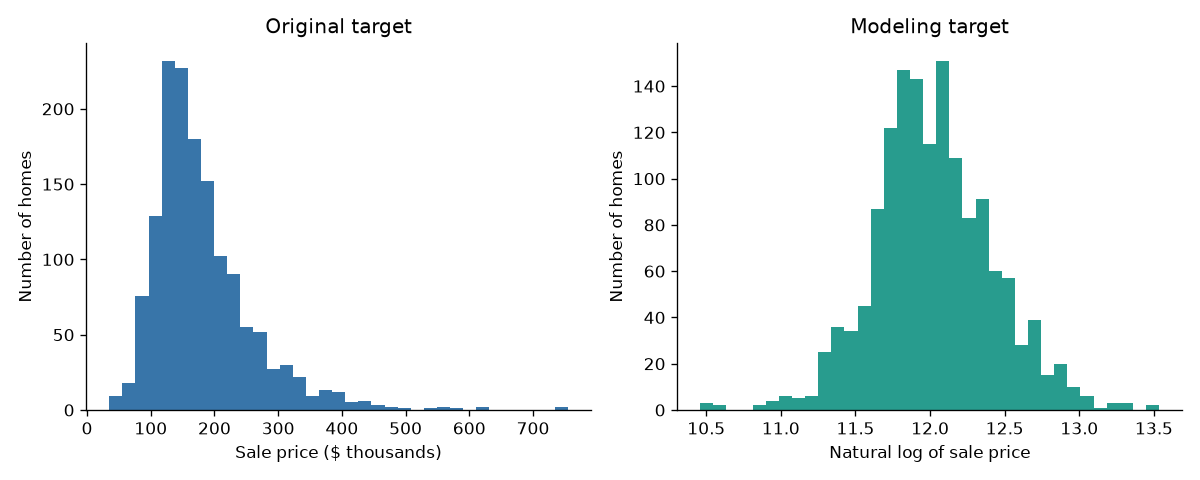

**02 model comparison**

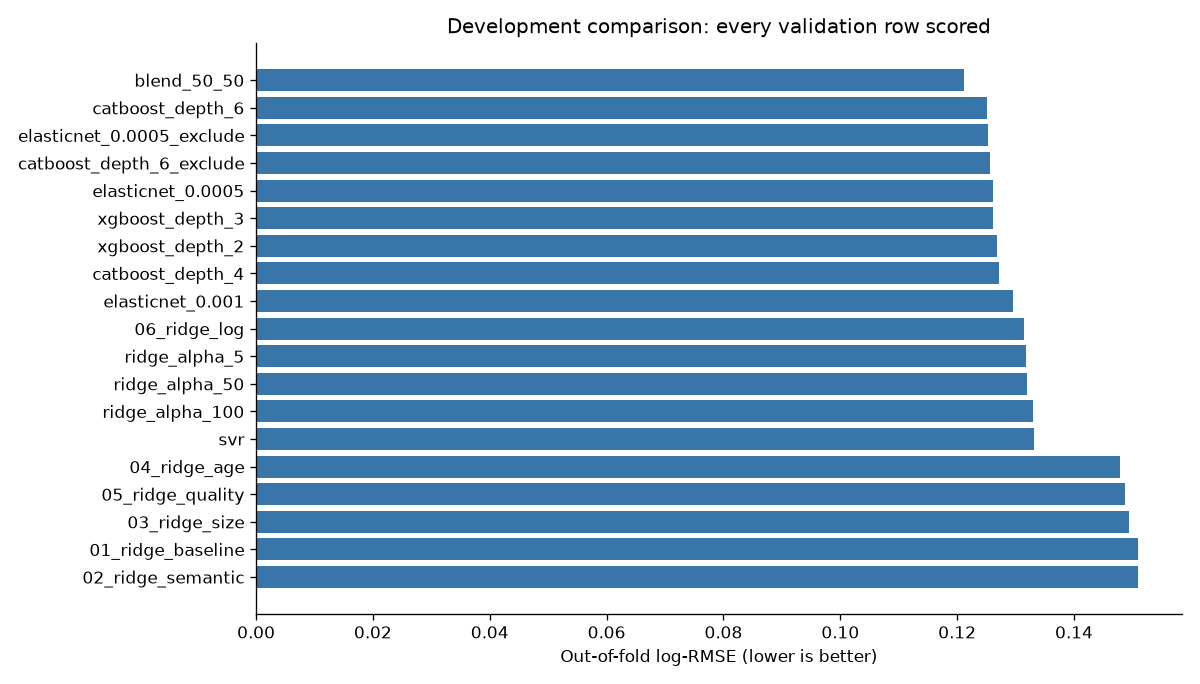

**03 feature ablation**

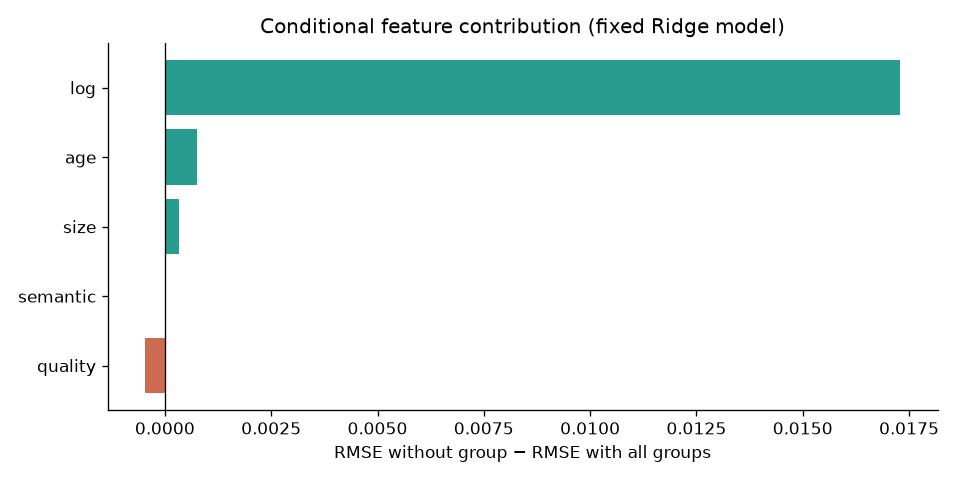

**04 error analysis**

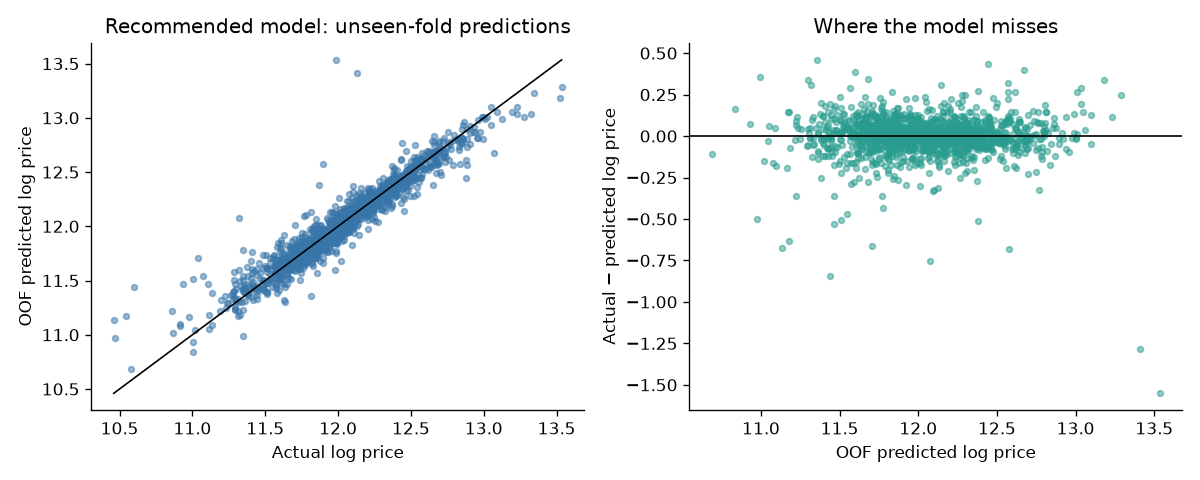

In [9]:
for figure in sorted((RESULTS / 'figures').glob('*.png')):
    display(Markdown('**' + figure.stem.replace('_', ' ').capitalize() + '**'))
    display(Image(filename=str(figure)))

## 7. Submission candidates and next decisions

The runner checks that each CSV has `Id,SalePrice`, uses the sample
submission's exact ID order, and contains a positive finite price for every
test home. Review the development and stability evidence before choosing a
candidate to upload. Record an actual Kaggle result separately after a manual
upload. The top 5% target remains an objective until the leaderboard shows it.

In [10]:
summary = json.loads((RESULTS / 'session_summary.json').read_text())
display(summary)
for candidate in sorted((OUTPUT_DIR / 'submissions').glob('*.csv')):
    print(candidate.name)

{'recommended_experiment': 'blend_50_50',
 'cv_log_rmse': 0.12116504082514586,
 'baseline_ridge_rmse': 0.15091290327146994,
 'blend_components': ['elasticnet_0.0005_exclude', 'catboost_depth_6'],
 'blend_cv_rmse': 0.12116504082514586,
 'experiments_run': 27,
 'validation_rows': 1460,
 'prediction_rows': 1459,
 'recommended_submission': 'submissions/recommended.csv',
 'kaggle_score': None,
 'kaggle_rank': None,
 'kaggle_submitted': False,
 'limitations': ['Models and features were selected using development cross-validation; selection optimism remains.',
  'Seed 2026 is a stability check, not an independent test set or confidence interval.',
  'Feature ablations are conditional on this fixed Ridge model; effects can interact.',
  'Outlier rule came from exploratory training-data analysis; all validation rows remain scored.',
  'Historical top-percentile notebook claims do not establish a current leaderboard cutoff.'],
 'stability': [{'experiment': 'elasticnet_0.0005_exclude',
   'seed42

00_constant.csv
01_ridge_baseline.csv
02_ridge_semantic.csv
03_ridge_size.csv
04_ridge_age.csv
05_ridge_quality.csv
06_ridge_log.csv
ablation_without_age.csv
ablation_without_log.csv
ablation_without_quality.csv
ablation_without_semantic.csv
ablation_without_size.csv
blend_50_50.csv
catboost_depth_4.csv
catboost_depth_6.csv
catboost_depth_6_exclude.csv
catboost_depth_6_seed2026.csv
elasticnet_0.0005.csv
elasticnet_0.0005_exclude.csv
elasticnet_0.0005_exclude_seed2026.csv
elasticnet_0.001.csv
kaggle_submission_log.csv
recommended.csv
ridge_alpha_100.csv
ridge_alpha_5.csv
ridge_alpha_50.csv
svr.csv
xgboost_depth_2.csv
xgboost_depth_3.csv
